In [8]:
#Se importan las librerías necesarias para los ejercicios siguientes
import numpy as np # importamos Numpy
import numpy.random as npr # para generar numeros aleeatorios
import matplotlib.pyplot as plt # Para graficar
import scipy.stats as sps # distribuciones 
from scipy.stats import bernoulli # importar cada distribución (añadir todas las distribuciones que vamos a usar)
from scipy.stats import hypergeom,binom, poisson, nbinom #HIPERGEOMETRICA

## Integrantes del equipo 3:
Conde Muñoz Diana Polet 

García Sánchez Ricardo Antonio 

Guzmán Méndez Evelyn 

Jaramillo Delgado Yeraldin María




$\color{red}{\text{Ejercicio 2.}}$ Un examen de Estadística consta de 20 preguntas tipo test y se conoce de experiencias
anteriores que un alumno tiene probabilidad 0.7 de contestar bien cada pregunta. Obtener:

a) La probabilidad de que la primera pregunta que contesta bien sea la cuarta.

b) Sabiendo que para aprobar el examen es necesario contestar bien a 10 preguntas, ¿cuál es la probabilidad de que apruebe al contestar la pregunta duodécima?

### Respuestas: 

a) Usaremos la v.a Geométrica, ya que cuenta el número de fracasos antes del primer éxito.

Sabemos que su pmf es: 

$$f_{X}(k)= p(1-p)^{k-1}$$

Para este caso $ X \sim \text{Geom}(0.7)$

Usando la pmf se tiene:

$$\mathbb{P}(X=4) = 0.7 (0.3)^3 = 0.0189$$

$\therefore \text{La probabilidad de que la primera pregunta que se contesta bien sea la cuarta es de}$ $0.0189$

In [9]:
#Verificando

import numpy as np
from scipy.stats import geom

#Parametros 
p=0.7
#Poobabilidad de que el primer exito ocurra en la pregunta 4
prob_4=geom.pmf(4,p)
prob_4

np.float64(0.018900000000000007)

b) Para este inciso usaremos la v.a Binomial Negativa, la cual describe procesos donde el número de éxitos está predeterminado ($r$), y nuestra incertidumbre recae sobre cuántos intentos totales ($X$) necesitaremos realizar.

Sabemos que su pmf es:

$$f_{X}(k) = \binom{k-1}{r-1} p^r (1-p)^{k-r}$$

En este caso $X \sim \text{BN(10, 0.7)} $

Usando la pmf se tiene: 

$$\mathbb{P}(X=12) = \binom{11}{9} 0.7^10 (0.3)^{2} \approx 0.139825 $$

$ \therefore \text{La probabilidad de aprobar el examen al contestar la duodécima pregunta es de}$ $0.139825$ aproximadamente.

In [10]:
#Verificando 

import scipy.stats as sps

#Parametros
r=10
p=0.7

# Probabilidad de aprobar el examen en la pregunta 12
prob_12 = sps.nbinom.pmf(12 - r, r, p)
prob_12

np.float64(0.13982524825499987)

$\color{red}{\text{Ejercicio 3.}}$ Investigue sobre el problema de la caja de cerillos de Banach y explique su solución (sin simulación).

## 1. Planteamiento del problema

El matemático Stefan Banach lleva dos cajas de cerillos: una en el bolsillo izquierdo y otra en el derecho. Cada caja contiene inicialmente $n$ cerillos.

Cada vez que necesita un cerillo, escoge uno de los dos bolsillos al azar, con probabilidad $1/2$ para cada uno, independientemente de las elecciones anteriores. Cuando escoge una caja vacía, se da cuenta por primera vez de que ya no contiene cerillos.

**Pregunta:** ¿Cuál es la probabilidad de que, cuando encuentre vacía una de las cajas, en la otra queden exactamente $k$ cerillos?

Definimos $X$ como la cantidad de cerillos restantes en la otra caja. Buscamos $P(X=k)$ para $k=0,1,\ldots,n$.

## 2. Conteo combinatorio 
**Paso 1.** Supongamos que se descubre vacía la caja izquierda y que en la derecha quedan $k$ cerillos.

Antes de intentar tomar un cerillo de la caja ya vacía, se realizaron exitosamente:

- $n$ extracciones de la caja izquierda, porque agotó todos sus cerillos.
- $n-k$ extracciones de la derecha, porque conservó $k$.

En total, las extracciones exitosas son

$$
n+(n-k)=2n-k.
$$

**Paso 2.** Contamos cuántos órdenes distintos de extracciones exitosas son posibles. De las $2n-k$ posiciones, elegimos cuáles corresponden a las $n$ extracciones de la caja izquierda:

$$
\binom{2n-k}{n}=\frac{(2n-k)!}{n!(n-k)!}.
$$

**Paso 3.** Cada orden específico de las $2n-k$ extracciones tiene probabilidad $(1/2)^{2n-k}$. Además, para *descubrir* que la izquierda está vacía, hay que escogerla una vez más, lo que añade un factor $1/2$:

$$
P(\text{izquierda vacía y derecha con }k)
=\binom{2n-k}{n}\left(\frac12\right)^{2n-k+1}.
$$

**Paso 4.** También puede ocurrir la situación simétrica: la derecha está vacía y en la izquierda quedan $k$. Los casos son excluyentes y tienen la misma probabilidad. Por ello, sumamos ambos casos:

$$
\begin{aligned}
P(X=k)
&=2\binom{2n-k}{n}\left(\frac12\right)^{2n-k+1}\\
&=\boxed{\binom{2n-k}{n}\left(\frac12\right)^{2n-k}},
\qquad k=0,1,\ldots,n.
\end{aligned}
$$

**Importante:** el enunciado se refiere a *encontrar* vacía la caja al escogerla otra vez; es distinto de preguntar qué sucede justo al sacar el último cerillo.

## 3. Ejemplo 

Supongamos que inicialmente cada caja tiene $n=3$ cerillos. Buscamos la probabilidad de que en la otra caja quede exactamente $k=1$ cerillo.

Sustituyendo en la expresión anterior:

$$
\begin{aligned}
P(X=1)
&=\binom{2(3)-1}{3}\left(\frac12\right)^{2(3)-1}\\
&=\binom{5}{3}\left(\frac12\right)^5\\
&=\frac{5!}{3!\,2!}\cdot\frac1{32}\\
&=\frac{10}{32}=\frac5{16}=0.3125.
\end{aligned}
$$

Por tanto, la probabilidad de que quede exactamente un cerillo en la otra caja es **31.25 %**.

## 4. Todas las probabilidades cuando $n=3$

$$
\begin{aligned}
P(X=0)&=\binom{6}{3}\left(\frac12\right)^6=\frac{20}{64}=0.3125,\\
P(X=1)&=\binom{5}{3}\left(\frac12\right)^5=\frac{10}{32}=0.3125,\\
P(X=2)&=\binom{4}{3}\left(\frac12\right)^4=\frac{4}{16}=0.25,\\
P(X=3)&=\binom{3}{3}\left(\frac12\right)^3=\frac18=0.125.
\end{aligned}
$$

Comprobamos matemáticamente que todas las probabilidades suman uno:

$$
0.3125+0.3125+0.25+0.125=1.
$$

## 5. Conclusión

El problema de Banach demuestra cómo una situación de elecciones aleatorias repetidas puede resolverse mediante combinaciones y las reglas básicas de probabilidad. La solución consiste en contar los órdenes posibles en que se extraen los cerillos de ambas cajas y multiplicarlos por la probabilidad de cada secuencia, teniendo en cuenta que cualquiera de las dos cajas puede descubrirse vacía.


## 6. Fuentes consultadas

- [Wolfram MathWorld: Banach Matchbox Problem](https://mathworld.wolfram.com/BanachMatchboxProblem.html).
- [Beyond STEP: Banach's Matchboxes](https://beyondstep.keithmcnulty.org/ch12/matchboxes.html).


$\color{red}{\text{Ejercicio 4.}}$ 

## Variable aleatoria Hipergeométrica con parámetros $n,N,m$.

Supongamos que se elige, **sin reemplazo**, una muestra de tamaño $n$ de una urna que contiene $N$ bolas, de las cuales $m$ son rojas y $N-m$ son verdes. Sea $X$ el número de bolas rojas seleccionadas, entonces su función de masa de probabilidades está dada por:
$$f_{X}(i)=
	\frac{\binom{m}{i}\binom{N-m}{n-i}}{\binom{N}{n}} \quad \text{si } i=0,1,\dots, n  
$$
Donde
- Los valores posibles de $X$ son 
$$ i=\max\{0,n-(N-m)\},\dots,\min\{n,m\}. $$

Notación. $X\sim \text{Hiper}(n,N,m)$.

Se tiene que
$$\mathbb{E}[X]=\frac{nm}{N}$$
y
$$\text{Var}[X]=\frac{nm}{N}\left[\frac{(n-1)(m-1)}{N-1}+1-\frac{nm}{N} \right].$$

Equivalentemente,

$$
\mathrm{Var}(X)=n\frac{m}{N}\left(1-\frac{m}{N}\right)\frac{N-n}{N-1}.
$$

**Nota.** Si $i\leq n$ y $X\sim \text{Hiper}(n,N,m)$, con $p=\frac{m}{N}$ y $m,N$ son muy grandes con respecto a $n$ e $i$, entonces
$$\mathbb{P}(X=i)\approx \binom{n}{i}p^{i}(1-p)^{n-i}.$$

Es decir, en poblaciones muy grandes, la distribución hipergeométrica puede aproximarse por una distribución binomial.

Ejercio replicar la grafica de la función de densidad

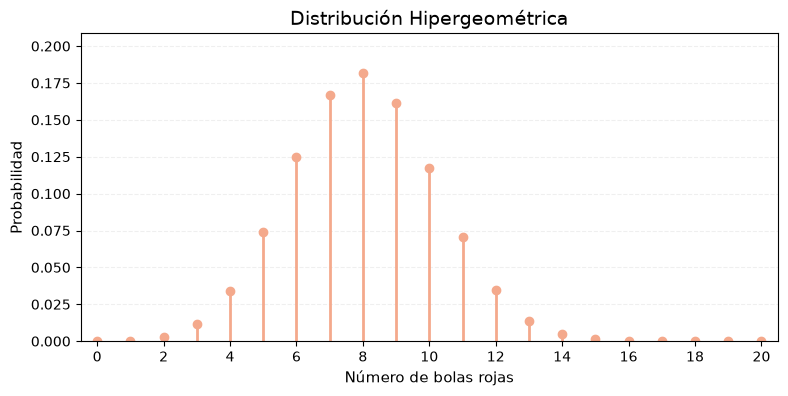

In [11]:
N = 1000  # Población total
m = 400   # Número de bolas rojas
n = 20    # Bolas seleccionadas sin reemplazo

x = np.arange(0, n+1)
y = hypergeom.pmf(x, N, m, n)

# Gráficamos
plt.figure(figsize=(9, 4))

plt.vlines(x, 0, y, color='#F4A98C', linewidth=2)
plt.plot(x, y, 'o', color='#F4A98C', markersize=6)

plt.title('Distribución Hipergeométrica', fontsize=14)
plt.xlabel('Número de bolas rojas', fontsize=11)
plt.ylabel('Probabilidad', fontsize=11)

plt.xticks(np.arange(0, n+1, 2))
plt.xlim(-0.5, n+0.5)
plt.ylim(0, np.max(y)*1.15)

plt.grid(axis='y', alpha=0.2, linestyle='--')
plt.show()


$\color{red}{\text{Ejercicio 5.}}$ Una compañía petrolera realiza un estudio geológico que indica que un pozo petrolero exploratorio debería tener un 20% de posibilidades de encontrar petróleo.

**¿Cuál es la probabilidad de que el primer pozo se produzca en el tercer pozo perforado?**

In [12]:
#  Probabilidad de éxito
p_exito = 0.20

# Ocurre en el 3er intento
k = 3 

# 1er éxito
r = 1

# P(X=3) 
prob_3 = nbinom.pmf(k - r, r, p_exito)

print("La probabilidad de que el 1er pozo se produzca en el 3er pozo perforado es:", prob_3)

La probabilidad de que el 1er pozo se produzca en el 3er pozo perforado es: 0.12799999999999997


**Probabilidad de que el 3er pozo se produzca en el 7mo pozo perforado**

In [13]:
# Ocurre en el 7mo intento
k2 = 7 

# 3er éxito
r2 = 3

# P (X = 7)
prob_7 = nbinom.pmf(k2 - r2, r2, p_exito)

print("La probabilidad de que el 3er pozo se produzca en el 7mo pozo perforado es:", prob_7)

La probabilidad de que el 3er pozo se produzca en el 7mo pozo perforado es: 0.04915200000000004


**¿Cuál es la media y la varianza del número de pozos que se deben perforar si la compañía petrolera quiere establecer tres pozos productores?**

In [14]:
# Número de éxitos
r3 = 3 

# Esperanza (Si se deja así estaríamos diciendo que necesito perforar 12 veces y fallar
# hasta que se logren 3 éxitos)
Esperanza = nbinom.mean(3, p_exito)
print("E[X] = ", Esperanza)

# Aquí decimos que en las 15 perforaciones se lograron los 3 éxitos que necesita la compañía
E = r3 / p_exito
print("\nE[X] = ", E)

# Varianza
Var = 3 * (1 - p_exito) / (p_exito ** 2)
print("\nVar[X] = ", Var)

E[X] =  12.000000000000002

E[X] =  15.0

Var[X] =  60.0
